# 5. Molecules: forces and geometry optimisation

jsiesta computes the forces on the atoms but has no built-in relaxation. Because calculations are Python
objects, any optimiser can drive them. This tutorial relaxes a water molecule with SciPy and measures its
bond length, angle and a vibrational frequency.

**You will learn** to set up an isolated molecule, read forces, and connect jsiesta to an external optimiser.

Run time: about two minutes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize

import jax_siesta as js

PSEUDOS = Path("../../examples/pseudos").resolve()
plt.rcParams["figure.dpi"] = 90

## A molecule in a box

Calculations are periodic, so an isolated molecule is placed in a cell large enough that the orbitals of
neighbouring images do not overlap. Only the Γ point is needed. The starting geometry below is deliberately
poor: bonds of 1.02 Å and an angle of 96°.

In [2]:
BOX = 8.0  # Ang
SYMBOLS = ["O", "H", "H"]


def water(positions):
    return js.make_structure(np.eye(3) * BOX, SYMBOLS, positions)


def geometry(positions):
    """O-H bond lengths (Ang) and H-O-H angle (degrees)."""
    v1, v2 = positions[1] - positions[0], positions[2] - positions[0]
    d1, d2 = np.linalg.norm(v1), np.linalg.norm(v2)
    return d1, d2, np.degrees(np.arccos(v1 @ v2 / (d1 * d2)))


d, half = 1.02, np.radians(96.0 / 2.0)
start = np.array([
    [4.0, 4.0, 4.0],
    [4.0 + d * np.sin(half), 4.0 + d * np.cos(half), 4.0],
    [4.0 - d * np.sin(half), 4.0 + d * np.cos(half), 4.0],
])
calc = js.Calculation.from_structure(
    water(start), PSEUDOS, basis="DZP", xc_functional="PBE", mesh_cutoff_ry=250.0, label="h2o",
)
first = calc.run()
print("energy (eV):", round(first.energy_ev, 5))
print("forces (eV/Ang):")
print(np.round(first.forces_ev_ang, 4))
print("sum of forces:", np.round(first.forces_ev_ang.sum(axis=0), 4))

energy (eV): -480.57337
forces (eV/Ang):
[[ 0.      3.3154 -0.    ]
 [-1.0602 -1.6188  0.    ]
 [ 1.0602 -1.6188 -0.    ]]
sum of forces: [ 0.      0.0779 -0.    ]


The forces pull the hydrogens towards the oxygen: the bonds are too long. Their sum is not exactly zero.
That residual, 0.08 eV/Ang here even at 250 Ry, is the egg-box effect of tutorial 2; the oxygen
pseudopotential is hard, which is the reason for the fairly high mesh cutoff used in this tutorial.

## Relaxation with SciPy

An optimiser needs a function that returns the energy and its gradient for a vector of coordinates. The
gradient of the energy is minus the forces.

In [3]:
history = []


def energy_and_gradient(x):
    positions = x.reshape(3, 3)
    r = calc.with_structure(water(positions)).run()
    history.append((r.energy_ev, np.abs(r.forces_ev_ang).max(), *geometry(positions)))
    return r.energy_ev, -r.forces_ev_ang.ravel()


opt = minimize(energy_and_gradient, start.ravel(), jac=True, method="BFGS", options={"gtol": 0.02})
relaxed = opt.x.reshape(3, 3)
history = np.array(history)
print(f"{len(history)} single points; largest force at the end: {history[-1, 1]:.4f} eV/Ang")
d1, d2, angle = geometry(relaxed)
print(f"O-H bond lengths: {d1:.4f}, {d2:.4f} Ang    H-O-H angle: {angle:.2f} degrees")

30 single points; largest force at the end: 0.0173 eV/Ang
O-H bond lengths: 0.9662, 0.9664 Ang    H-O-H angle: 105.01 degrees


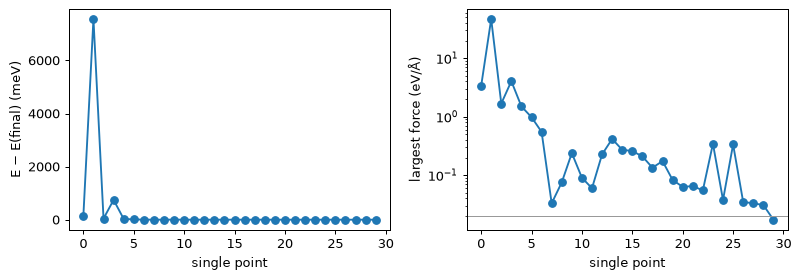

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
ax1.plot((history[:, 0] - history[-1, 0]) * 1000.0, "o-")
ax1.set_xlabel("single point")
ax1.set_ylabel("E − E(final) (meV)")
ax2.semilogy(history[:, 1], "o-")
ax2.axhline(0.02, color="0.6", lw=0.8)
ax2.set_xlabel("single point")
ax2.set_ylabel("largest force (eV/Å)")
fig.tight_layout()

Experiment gives 0.957 Å and 104.5°; PBE with a large basis gives about 0.97 Å and 104.2°. The slightly
longer bond is characteristic of PBE. The optimiser needs more steps than a noise-free problem of nine
variables would, because of the egg-box ripple in the forces.

Each single point after the first is fast because the compiled functions are reused: the arrays keep their
shapes when atoms move a little.

## A vibrational frequency by finite differences

With the forces one can also get force constants. For the symmetric stretch we move both hydrogens along
their bonds by ±δ and take the second derivative of the energy from the change of the force.

In [5]:
def stretched(delta):
    pos = relaxed.copy()
    for i in (1, 2):
        bond = relaxed[i] - relaxed[0]
        pos[i] = relaxed[0] + bond * (1.0 + delta / np.linalg.norm(bond))
    return pos


def force_along_bonds(delta):
    r = calc.with_structure(water(stretched(delta))).run()
    f = 0.0
    for i in (1, 2):
        bond = relaxed[i] - relaxed[0]
        f += r.forces_ev_ang[i] @ bond / np.linalg.norm(bond)
    return f  # generalised force for the coordinate "both bonds longer by delta"


delta = 0.01  # Ang
k = -(force_along_bonds(delta) - force_along_bonds(-delta)) / (2.0 * delta)  # eV/Ang^2

# Both H atoms move by delta: the kinetic energy is (1/2)(2 m_H) delta_dot^2 if the oxygen is taken as fixed.
EV_ANG2_AMU_TO_CM1 = 521.47  # sqrt(eV / Ang^2 / amu) in cm^-1
omega = EV_ANG2_AMU_TO_CM1 * np.sqrt(k / (2.0 * 1.008))
print(f"force constant: {k:.2f} eV/Ang^2   symmetric-stretch frequency (fixed O, pure stretch): {omega:.0f} cm^-1")

force constant: 98.83 eV/Ang^2   symmetric-stretch frequency (fixed O, pure stretch): 3651 cm^-1


The experimental harmonic symmetric-stretch frequency is 3832 cm⁻¹. Our estimate ignores the motion of the
oxygen and the small bending component of the true normal mode; the exercises refine it.

## Exercises

1. **H₂.** Compute the energy of H₂ for bond lengths between 0.60 and 0.95 Å, fit a parabola near the
   minimum, and obtain the equilibrium bond length and the vibrational frequency (reduced mass
   $m_H/2$). Experiment: 0.741 Å and 4401 cm⁻¹. Pass `split_norm_h=0.5` to `from_structure`; tutorial 7
   explains why hydrogen needs it. *(Solution in the Solutions notebook.)*
2. Is the 8 Å box large enough? Repeat the first single point with 10 and 12 Å. Which changes more, the
   energy or the forces? (The longest orbital radius is printed by `calc.run(log=print)`.)
3. Repeat the relaxation with `mesh_cutoff_ry=100`. Does the optimiser still converge to 0.02 eV/Å? Look at
   the sum of the forces along the way.
4. Build the full 9 x 9 matrix of force constants by displacing each atom along x, y and z, mass-weight it
   and diagonalise it. You should find three vibrations (two stretches near 3700 to 3900 cm⁻¹ and a bend near
   1600 cm⁻¹) and six modes near zero. How far from zero are those, and what does that tell you?